# Linguistic Bigram frequencies in ED

This notebook counts the **bigram tokens actually emitted** by the current original TVA linguistic tokenizer, whose vocabulary was trained on IAM text. It only loads the frozen vocabulary; it does not train on ED.

Both **WD and WI** are displayed by default. Change `FOLD` and `TOP_N` below; set `SPLITS` to `['wd']` or `['wi']` to display only one. Train and validation together cover the complete ED dataset once. Counts preserve case, spaces and punctuation, and repeated sentence recordings each contribute to the counts. These are greedy-token frequencies, not counts of every overlapping two-character substring.

WD and WI contain the same recordings, so their pooled frequencies match. Their train/validation frequencies can differ because the folds are defined differently.


In [10]:
%matplotlib inline
import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import yaml
from IPython.display import Markdown, display
from tva.tokenizers import BigramTokenizer

ROOT = Path.cwd()  # Run from the TVA repository folder.
SPLITS = ['wd', 'wi']  # Display both; use ['wd'] or ['wi'] for one.
FOLD = 0           # 0, 1, 2, 3 or 4
TOP_N = 30         # Set to 145 to display every vocabulary bigram.

config = yaml.safe_load((ROOT / f'configs/thesis/ed/bigram_tva_original_{SPLITS[0]}.yaml').read_text())
tokenizer = BigramTokenizer()
tokenizer.load(ROOT / config['dir_tokenizer'])
bigrams = [token for token in tokenizer.vocab if len(token) == 2]
print(f'Loaded {len(bigrams)} linguistic bigrams ({tokenizer.size} total classes including blank).')


2026-10-17 22:26:09.966 | INFO     | tva.tokenizers:load:214 - BigramTokenizer is loaded from /home/artellisys/TVA/artifacts/tokenizers/ed/linguistic/ed_iam_tva_original_bigram_greedy_v1.json.


Loaded 145 linguistic bigrams (224 total classes including blank).


## Count emitted bigrams

Each recording is encoded using TVA's actual greedy encoder. Singleton fallback tokens and CTC blank are excluded from the bigram-frequency counts.


In [11]:
def count_bigrams(records):
    counts = Counter()
    for record in records:
        ids = tokenizer.encode(record['label'])
        counts.update(tokenizer.idx_token[i] for i in ids if len(tokenizer.idx_token[i]) == 2)
    return counts


results = {}
for split in SPLITS:
    dataset = ROOT / f'data/tva/ed/gold_{split}'
    train = json.loads((dataset / 'train.json').read_text())['annotations'][str(FOLD)]
    val = json.loads((dataset / 'val.json').read_text())['annotations'][str(FOLD)]
    train_counts = count_bigrams(train)
    val_counts = count_bigrams(val)
    results[split] = {
        'train': train_counts, 'val': val_counts,
        'all': train_counts + val_counts,
        'train_total': sum(train_counts.values()),
        'val_total': sum(val_counts.values()),
    }
    print(f'{split.upper()} fold {FOLD}: {len(train)} train + {len(val)} validation recordings')
    print(f'Bigram tokens: {sum(train_counts.values()):,} train + {sum(val_counts.values()):,} validation')

all_counts = results[SPLITS[0]]['all']
assert all(r['all'] == all_counts for r in results.values())
total = sum(all_counts.values())
ranked = sorted(bigrams, key=lambda token: (-all_counts[token], token))
top = ranked[:TOP_N]
unused = [token for token in bigrams if all_counts[token] == 0]
print(f'Pooled ED bigram tokens: {total:,}; vocabulary bigrams used: {len(bigrams) - len(unused)}/{len(bigrams)}')
print('Unused bigrams:', unused)


WD fold 0: 2047 train + 503 validation recordings
Bigram tokens: 28,080 train + 7,241 validation
WI fold 0: 2025 train + 525 validation recordings
Bigram tokens: 27,961 train + 7,360 validation
Pooled ED bigram tokens: 35,321; vocabulary bigrams used: 145/145
Unused bigrams: []


## Frequency tables — WD and WI

Each split has its own train and validation counts. `Frequency (%)` uses all emitted bigram tokens across train + validation as its denominator, so the total-frequency column is identical for WD and WI. `repr()` makes spaces visible; for example, `'e '` includes a trailing space. Set `TOP_N = 145` above to display the full vocabulary.


In [12]:
for split, counts in results.items():
    display(Markdown(f'### {split.upper()} — fold {FOLD}'))
    lines = [
        '| Bigram | ID | Train count | Validation count | Total count | Frequency (%) |',
        '| --- | ---: | ---: | ---: | ---: | ---: |',
    ]
    for token in top:
        shown = repr(token).replace('|', chr(92) + '|')
        lines.append(f"| {shown} | {tokenizer.vocab[token]} | {counts['train'][token]} | {counts['val'][token]} | {counts['all'][token]} | {100 * counts['all'][token] / total:.3f} |")
    display(Markdown(chr(10).join(lines)))


### WD — fold 0

| Bigram | ID | Train count | Validation count | Total count | Frequency (%) |
| --- | ---: | ---: | ---: | ---: | ---: |
| 'e ' | 79 | 1140 | 287 | 1427 | 4.040 |
| 's ' | 83 | 746 | 196 | 942 | 2.667 |
| 't ' | 86 | 695 | 182 | 877 | 2.483 |
| 'th' | 81 | 561 | 178 | 739 | 2.092 |
| 'n ' | 89 | 548 | 149 | 697 | 1.973 |
| 'in' | 85 | 560 | 123 | 683 | 1.934 |
| ' t' | 80 | 527 | 136 | 663 | 1.877 |
| 'y ' | 99 | 513 | 130 | 643 | 1.820 |
| ', ' | 103 | 553 | 86 | 639 | 1.809 |
| ' a' | 84 | 471 | 112 | 583 | 1.651 |
| 're' | 91 | 449 | 120 | 569 | 1.611 |
| 'er' | 87 | 403 | 120 | 523 | 1.481 |
| 'Th' | 205 | 367 | 130 | 497 | 1.407 |
| ' i' | 97 | 389 | 103 | 492 | 1.393 |
| 'at' | 96 | 410 | 72 | 482 | 1.365 |
| 'on' | 92 | 402 | 76 | 478 | 1.353 |
| 'is' | 100 | 386 | 89 | 475 | 1.345 |
| 'an' | 90 | 347 | 102 | 449 | 1.271 |
| 'he' | 82 | 370 | 73 | 443 | 1.254 |
| ' w' | 95 | 347 | 71 | 418 | 1.183 |
| ' o' | 94 | 322 | 92 | 414 | 1.172 |
| 'd ' | 88 | 306 | 100 | 406 | 1.149 |
| 'ou' | 120 | 320 | 85 | 405 | 1.147 |
| 'r ' | 98 | 336 | 56 | 392 | 1.110 |
| ' s' | 101 | 316 | 69 | 385 | 1.090 |
| 'or' | 109 | 254 | 114 | 368 | 1.042 |
| 'al' | 125 | 254 | 102 | 356 | 1.008 |
| 'te' | 112 | 270 | 80 | 350 | 0.991 |
| 'ar' | 110 | 276 | 65 | 341 | 0.965 |
| 'le' | 128 | 260 | 79 | 339 | 0.960 |

### WI — fold 0

| Bigram | ID | Train count | Validation count | Total count | Frequency (%) |
| --- | ---: | ---: | ---: | ---: | ---: |
| 'e ' | 79 | 1156 | 271 | 1427 | 4.040 |
| 's ' | 83 | 741 | 201 | 942 | 2.667 |
| 't ' | 86 | 684 | 193 | 877 | 2.483 |
| 'th' | 81 | 587 | 152 | 739 | 2.092 |
| 'n ' | 89 | 540 | 157 | 697 | 1.973 |
| 'in' | 85 | 539 | 144 | 683 | 1.934 |
| ' t' | 80 | 504 | 159 | 663 | 1.877 |
| 'y ' | 99 | 507 | 136 | 643 | 1.820 |
| ', ' | 103 | 512 | 127 | 639 | 1.809 |
| ' a' | 84 | 463 | 120 | 583 | 1.651 |
| 're' | 91 | 445 | 124 | 569 | 1.611 |
| 'er' | 87 | 401 | 122 | 523 | 1.481 |
| 'Th' | 205 | 403 | 94 | 497 | 1.407 |
| ' i' | 97 | 383 | 109 | 492 | 1.393 |
| 'at' | 96 | 374 | 108 | 482 | 1.365 |
| 'on' | 92 | 383 | 95 | 478 | 1.353 |
| 'is' | 100 | 376 | 99 | 475 | 1.345 |
| 'an' | 90 | 347 | 102 | 449 | 1.271 |
| 'he' | 82 | 349 | 94 | 443 | 1.254 |
| ' w' | 95 | 340 | 78 | 418 | 1.183 |
| ' o' | 94 | 312 | 102 | 414 | 1.172 |
| 'd ' | 88 | 331 | 75 | 406 | 1.149 |
| 'ou' | 120 | 332 | 73 | 405 | 1.147 |
| 'r ' | 98 | 314 | 78 | 392 | 1.110 |
| ' s' | 101 | 320 | 65 | 385 | 1.090 |
| 'or' | 109 | 300 | 68 | 368 | 1.042 |
| 'al' | 125 | 275 | 81 | 356 | 1.008 |
| 'te' | 112 | 278 | 72 | 350 | 0.991 |
| 'ar' | 110 | 274 | 67 | 341 | 0.965 |
| 'le' | 128 | 255 | 84 | 339 | 0.960 |

## Frequency plots

First figure: WD and WI side by side, showing train/validation frequencies for the same top bigrams. Each partition is normalized by its own emitted bigram-token total.

Second figure: the frequency histogram over all 145 vocabulary bigrams, including unused ones. This pooled histogram is shared by WD and WI because both contain the same recordings. Its vertical axis counts vocabulary entries, not recordings.


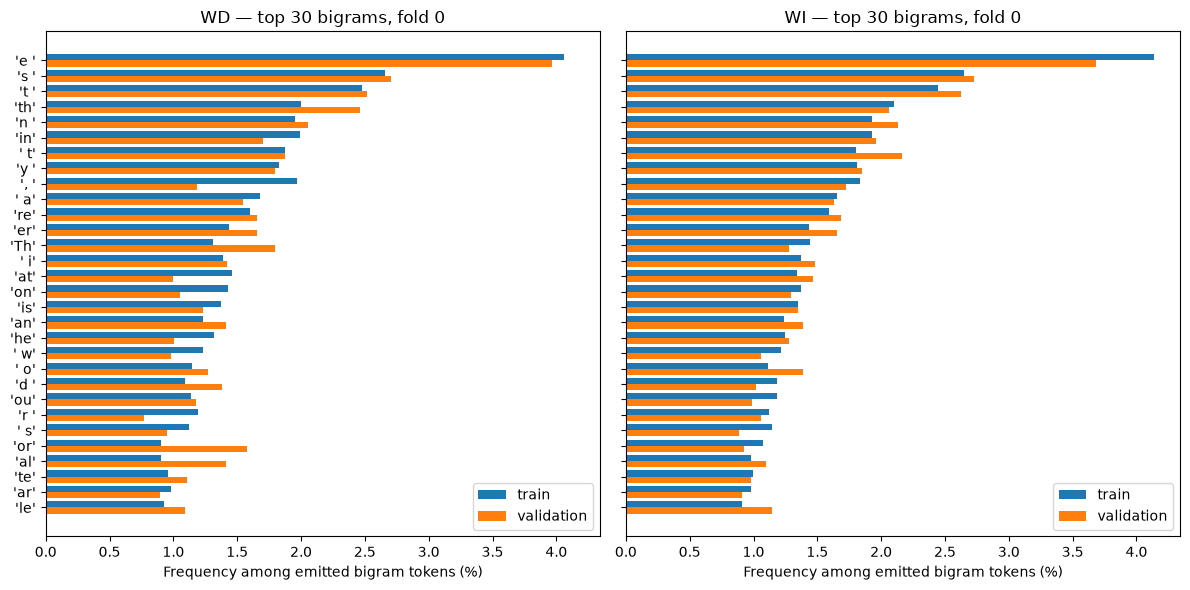

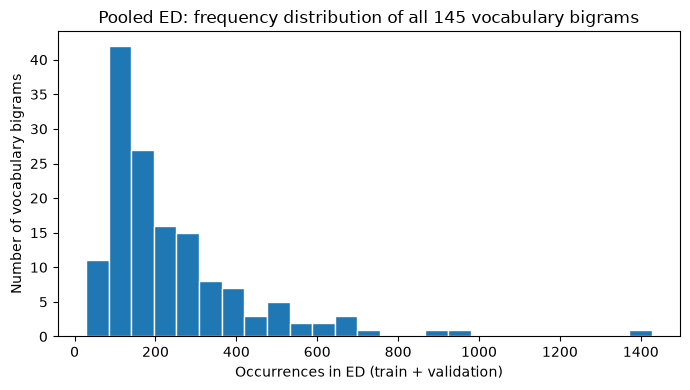

In [13]:
fig, axes = plt.subplots(1, len(SPLITS), figsize=(6 * len(SPLITS), 6), sharex=True, sharey=True, squeeze=False)
y = list(range(len(top)))
for ax, split in zip(axes[0], SPLITS):
    counts = results[split]
    ax.barh([i - 0.2 for i in y], [100 * counts['train'][t] / counts['train_total'] for t in top], height=0.4, label='train')
    ax.barh([i + 0.2 for i in y], [100 * counts['val'][t] / counts['val_total'] for t in top], height=0.4, label='validation')
    ax.set_yticks(y, [repr(t) for t in top])
    ax.set_title(f'{split.upper()} — top {len(top)} bigrams, fold {FOLD}')
    ax.set_xlabel('Frequency among emitted bigram tokens (%)')
    ax.legend()
axes[0, 0].invert_yaxis()
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
plt.hist([all_counts[t] for t in bigrams], bins=25, edgecolor='white')
plt.title(f'Pooled ED: frequency distribution of all {len(bigrams)} vocabulary bigrams')
plt.xlabel('Occurrences in ED (train + validation)')
plt.ylabel('Number of vocabulary bigrams')
plt.tight_layout()
plt.show()
